In [1]:
import os 
from os.path import join
import numpy as np 
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.models import Model 
from tensorflow.keras.layers import Dense , Dropout , GlobalAveragePooling2D

In [2]:
dataset_path="/kaggle/input/melanoma/DermMel"
files=os.listdir(dataset_path)
print("the flies in folder is ", files)


the flies in folder is  ['valid', 'test', 'train_sep']


In [3]:
# Define the paths for training, testing, and validation sets
train_path=os.path.join(dataset_path,"train_sep")
test_path=os.path.join(dataset_path,"test")
valid_path=os.path.join(dataset_path,"valid")
# Check the categories in each set
print("the categories on train_set is : ",os.listdir(train_path))
print("the categories on test_set is : ",os.listdir(test_path))
print("the categories on validation_set is : ",os.listdir(valid_path))

the categories on train_set is :  ['Melanoma', 'NotMelanoma']
the categories on test_set is :  ['Melanoma', 'NotMelanoma']
the categories on validation_set is :  ['Melanoma', 'NotMelanoma']


In [4]:

# Set the directory paths
train_dir=train_path
val_dir=valid_path
test_dir=test_path
# ImageDataGenerator for data augmentation and normalization
train_datagen=ImageDataGenerator(rescale=1./255)
val_datagen=ImageDataGenerator(rescale=1./255)
test_datagen=ImageDataGenerator(rescale=1./255)

# Generators for training, validation, and testing datasets
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical"
)
val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical"
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical"
    
)


Found 10682 images belonging to 2 classes.
Found 3562 images belonging to 2 classes.
Found 3561 images belonging to 2 classes.


In [5]:
# Print the class indices for each generator
print(train_generator.class_indices)
print(val_generator.class_indices)
print(test_generator.class_indices)      

{'Melanoma': 0, 'NotMelanoma': 1}
{'Melanoma': 0, 'NotMelanoma': 1}
{'Melanoma': 0, 'NotMelanoma': 1}


In [6]:

base_model = EfficientNetB0(weights=None, include_top=False, input_shape=(224, 224, 3))
# Extract the output of the base model (without the top layers)
x = base_model.output

# Apply Global Average Pooling to reduce the spatial dimensions and prepare for dense layers
x = GlobalAveragePooling2D()(x)

# Add a fully connected (dense) layer with 512 units and ReLU activation
x = Dense(512, activation="relu")(x)

# Add dropout to reduce overfitting (30% of neurons dropped during training)
x = Dropout(0.3)(x)

# Final output layer with 2 units (melanoma vs. not melanoma) using softmax activation
outputs = Dense(2, activation="softmax")(x)

# Create the full model by connecting the base input to the custom output
model = Model(inputs=base_model.input, outputs=outputs)

# Compile the model with Adam optimizer and categorical crossentropy loss for classification
model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)  │ (None, 224, 224, 3)    │              0 │ -                      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ rescaling (Rescaling)     │ (None, 224, 224, 3)    │              0 │ input_layer[0][0]      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ normalization             │ (None, 224, 224, 3)    │              7 │ rescaling[0][0]        │
│ (Normalization)           │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ stem_conv_pad             │ (None, 225, 225, 3)    │              0 │ normalization[0][0]    │
│ (ZeroPadding2D)           │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ stem_conv (Conv2D)        │ (None, 112, 112, 32)   │            864 │ stem_conv_pad[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ stem_bn                   │ (None, 112, 112, 32)   │            128 │ stem_conv[0][0]        │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ stem_activation           │ (None, 112, 112, 32)   │              0 │ stem_bn[0][0]          │
│ (Activation)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block1a_dwconv            │ (None, 112, 112, 32)   │            288 │ stem_activation[0][0]  │
│ (DepthwiseConv2D)         │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block1a_bn                │ (None, 112, 112, 32)   │            128 │ block1a_dwconv[0][0]   │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block1a_activation        │ (None, 112, 112, 32)   │              0 │ block1a_bn[0][0]       │
│ (Activation)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block1a_se_squeeze        │ (None, 32)             │              0 │ block1a_activation[0]… │
│ (GlobalAveragePooling2D)  │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block1a_se_reshape        │ (None, 1, 1, 32)       │              0 │ block1a_se_squeeze[0]… │
│ (Reshape)                 │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block1a_se_reduce         │ (None, 1, 1, 8)        │            264 │ block1a_se_reshape[0]… │
│ (Conv2D)                  │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block1a_se_expand         │ (None, 1, 1, 32)       │            288 │ block1a_se_reduce[0][… │
│ (Conv2D)                  │                        │                │                        │
├──────────────────────

 Total params: 4,706,469 (17.95 MB)

 Trainable params: 4,664,446 (17.79 MB)

 Non-trainable params: 42,023 (164.16 KB)

In [7]:
from tensorflow.keras.callbacks import EarlyStopping

# Initialize EarlyStopping to prevent overfitting during training
early_stopping = EarlyStopping(
    monitor="val_loss",           # Monitor the validation loss to detect overfitting
    patience=5,                   # Stop training if no improvement for 5 consecutive epochs
    restore_best_weights=True     # Restore the model weights from the epoch with the best val_loss
)

In [8]:
history = model.fit(
    train_generator,               # The training data generator
    validation_data=val_generator, # The validation data generator
    epochs=30,                     # Maximum number of training epochs
    callbacks=[early_stopping]     # Use EarlyStopping to prevent overfitting
)

Epoch 1/30


/usr/local/lib/python3.10/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


334/334 ━━━━━━━━━━━━━━━━━━━━ 277s 623ms/step - accuracy: 0.7371 - loss: 0.6213 - val_accuracy: 0.5000 - val_loss: 3.1100
Epoch 2/30
334/334 ━━━━━━━━━━━━━━━━━━━━ 66s 196ms/step - accuracy: 0.8913 - loss: 0.2832 - val_accuracy: 0.9149 - val_loss: 0.2535
Epoch 3/30
334/334 ━━━━━━━━━━━━━━━━━━━━ 65s 192ms/step - accuracy: 0.9269 - loss: 0.1899 - val_accuracy: 0.9351 - val_loss: 0.1864
Epoch 4/30
334/334 ━━━━━━━━━━━━━━━━━━━━ 66s 193ms/step - accuracy: 0.9352 - loss: 0.1629 - val_accuracy: 0.9399 - val_loss: 0.1667
Epoch 5/30
334/334 ━━━━━━━━━━━━━━━━━━━━ 66s 193ms/step - accuracy: 0.9446 - loss: 0.1408 - val_accuracy: 0.9396 - val_loss: 0.1630
Epoch 6/30
334/334 ━━━━━━━━━━━━━━━━━━━━ 67s 197ms/step - accuracy: 0.9485 - loss: 0.1286 - val_accuracy: 0.9015 - val_loss: 0.2194
Epoch 7/30
334/334 ━━━━━━━━━━━━━━━━━━━━ 66s 193ms/step - accuracy: 0.9529 - loss: 0.1212 - val_accuracy: 0.9225 - val_loss: 0.2822
Epoch 8/30
334/334 ━━━━━━━━━━━━━━━━━━━━ 66s 194ms/step - accuracy: 0.9612 - loss: 0.0977 - va

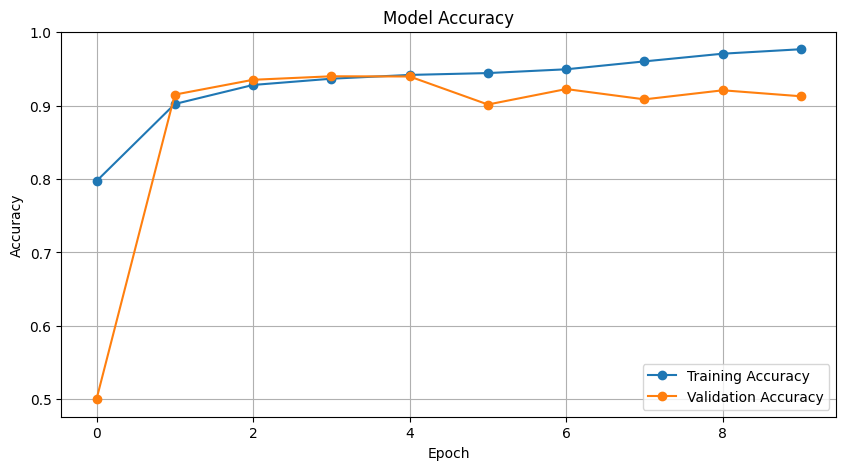

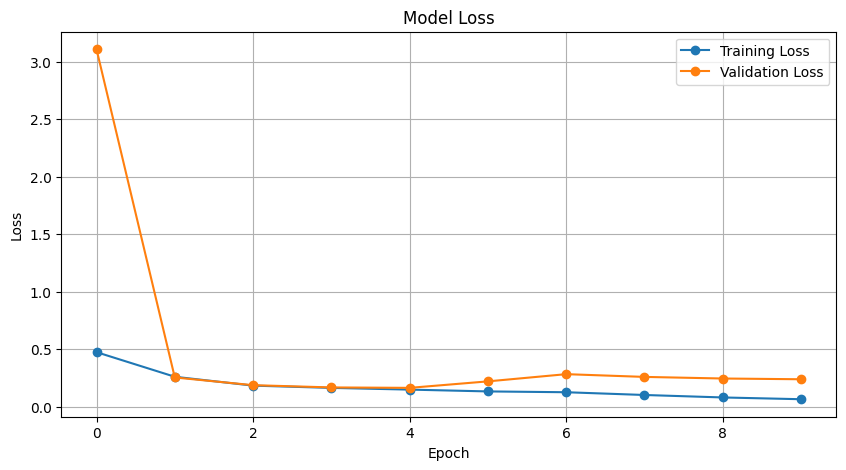

In [25]:
import matplotlib.pyplot as plt
# Training and validation accuracy chart
plt.figure(figsize=(10, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy', marker='o')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', marker='o')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Training and verification loss chart
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Training Loss', marker='o')
plt.plot(history.history['val_loss'], label='Validation Loss', marker='o')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

In [9]:
# Evaluate the model's performance on the unseen test data
test_loss, test_acc = model.evaluate(test_generator)

# Display the test accuracy in percentage format
print(f"Test Accuracy : {test_acc*100:.2f}%")


112/112 ━━━━━━━━━━━━━━━━━━━━ 46s 413ms/step - accuracy: 0.9461 - loss: 0.1093
Test Accuracy : 93.12%


In [ ]:
model.save("/kaggle/working/melanoma_model_v4.h5")